<a href="https://colab.research.google.com/github/nivethashrikm08-blip/MLA0202-FML/blob/main/EXP%2019.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Bank Loan Prediction using Naive Bayes
Accuracy: 100.0 %
Loan Approved


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but GaussianNB was fitted with feature names
  warnings.warn(


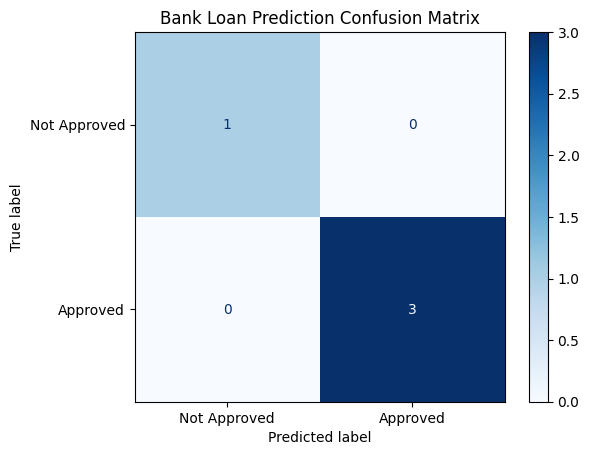

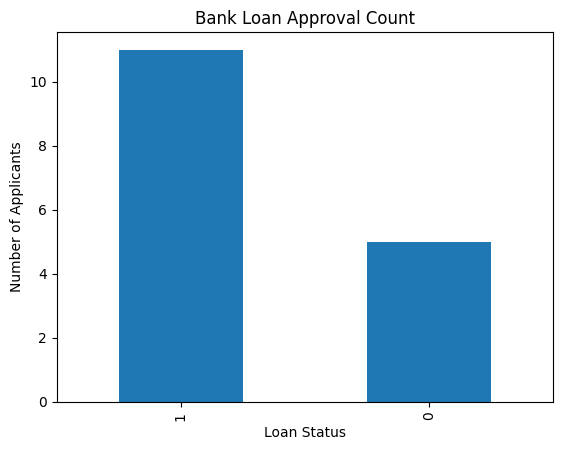

In [1]:
# EXPERIMENT 19: BANK LOAN PREDICTION USING NAIVE BAYES

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# Sample bank loan dataset
data = pd.DataFrame({
    "Job": [
        "Salaried", "Business", "Salaried", "Business",
        "Salaried", "Business", "Salaried", "Business",
        "Salaried", "Business", "Salaried", "Business",
        "Salaried", "Business", "Salaried", "Business"
    ],
    "Credit_History": [
        "Good", "Good", "Good", "Poor",
        "Poor", "Good", "Good", "Poor",
        "Good", "Good", "Poor", "Good",
        "Good", "Poor", "Good", "Good"
    ],
    "Income": [
        "High", "High", "Medium", "High",
        "Low", "Medium", "High", "Low",
        "Medium", "High", "Low", "Medium",
        "High", "Low", "Medium", "High"
    ],
    "Loan_Approved": [
        "Yes", "Yes", "Yes", "No",
        "No", "Yes", "Yes", "No",
        "Yes", "Yes", "No", "Yes",
        "Yes", "No", "Yes", "Yes"
    ]
})

# Convert categorical data into numbers
encoder = LabelEncoder()

for column in data.columns:
    data[column] = encoder.fit_transform(data[column])

X = data[["Job", "Credit_History", "Income"]]
y = data["Loan_Approved"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

model = GaussianNB()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Bank Loan Prediction using Naive Bayes")
print("Accuracy:", accuracy_score(y_test, y_pred) * 100, "%")

# Predict new applicant
# Values: Salaried=1, Good credit=0, High income=0
new_applicant = [[1, 0, 0]]

prediction = model.predict(new_applicant)

if prediction[0] == 1:
    print("Loan Approved")
else:
    print("Loan Not Approved")

# Graph 1: Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

ConfusionMatrixDisplay(
    cm, display_labels=["Not Approved", "Approved"]
).plot(cmap="Blues")

plt.title("Bank Loan Prediction Confusion Matrix")
plt.show()

# Graph 2: Loan Approval Count
data["Loan_Approved"].value_counts().plot(kind="bar")

plt.xlabel("Loan Status")
plt.ylabel("Number of Applicants")
plt.title("Bank Loan Approval Count")
plt.show()